# Notebook 01: Exploration and Preprocessing
**Project:** Real vs. Synthetic Data: Comparative Analysis and Visualization
**Dataset:** Online Shoppers Purchasing Intention (UCI Machine Learning Repository, id 468; Sakar et al., 2019)

This notebook (1) explores the original file, (2) cleans it step by step, (3) records every decision in a preprocessing log, and (4) saves a **separate** cleaned dataset. The original file is only ever read, never written; its SHA-256 hash is checked at the start and the end.

## 0. Setup

In [1]:
import hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
SEED = 42                      # fixed seed for reproducibility
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})

# Find the project root (the folder that contains data/) so the notebook runs from anywhere
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
ORIG_PATH  = ROOT / "data" / "original" / "online_shoppers_intention.csv"
CLEAN_PATH = ROOT / "data" / "cleaned" / "online_shoppers_cleaned.csv"
LOG_PATH   = ROOT / "data" / "cleaned" / "preprocessing_log.csv"
FIG_DIR    = ROOT / "figures" / "real" / "exploration"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

ORIG_HASH = sha256(ORIG_PATH)
print("Project root :", ROOT)
print("Original SHA :", ORIG_HASH)

Project root : /home/claude/real-vs.-synthetic-data-comparative-analysis-and-visualization
Original SHA : b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9


## 1. Load the original data (read-only)

In [2]:
raw = pd.read_csv(ORIG_PATH)
df = raw.copy()          # all cleaning happens on this copy; `raw` stays as loaded
print("Shape:", raw.shape)
raw.head()

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. Exploration of the original data

### 2.1 Structure: data types, unique values, missing values

In [3]:
structure = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "n_missing": raw.isna().sum(),
    "share_zero_%": (raw.select_dtypes("number") == 0).mean().mul(100).round(1).reindex(raw.columns),
})
display(structure)
print("Total missing cells:", int(raw.isna().sum().sum()))
print("Exact duplicate rows:", int(raw.duplicated().sum()))

,dtype,n_unique,n_missing,share_zero_%
Administrative,int64,27,0,46.8
Administrative_Duration,float64,3335,0,47.9
Informational,int64,17,0,78.7
Informational_Duration,float64,1258,0,80.5
ProductRelated,int64,311,0,0.3
ProductRelated_Duration,float64,9551,0,6.1
BounceRates,float64,1872,0,44.8
ExitRates,float64,4777,0,0.6
PageValues,float64,2704,0,77.9
SpecialDay,float64,6,0,89.9


Total missing cells: 0
Exact duplicate rows: 125


**Reading the table.** There are no missing cells, so the missing-value step only has to confirm this. `Weekend` and `Revenue` are stored as booleans, and `OperatingSystems`, `Browser`, `Region` and `TrafficType` are stored as integers although they are anonymous category codes, so their types need fixing. Several numeric columns are mostly zeros (see `share_zero_%`), which matters for outlier handling later.

### 2.2 Categorical columns

In [4]:
cat_cols_raw = ["Month", "VisitorType", "Weekend", "Revenue",
                "OperatingSystems", "Browser", "Region", "TrafficType"]
for c in cat_cols_raw:
    vc = raw[c].value_counts(dropna=False)
    print(f"--- {c} ({raw[c].nunique()} unique)")
    print(vc.head(12).to_string())
    print()

--- Month (10 unique)
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184

--- VisitorType (3 unique)
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85

--- Weekend (2 unique)
Weekend
False    9462
True     2868

--- Revenue (2 unique)
Revenue
False    10422
True      1908

--- OperatingSystems (8 unique)
OperatingSystems
2    6601
1    2585
3    2555
4     478
8      79
6      19
7       7
5       6

--- Browser (13 unique)
Browser
2     7961
1     2462
4      736
5      467
6      174
10     163
8      135
3      105
13      61
7       49
12      10
11       6

--- Region (9 unique)
Region
1    4780
3    2403
4    1182
2    1136
6     805
7     761
9     511
8     434
5     318

--- TrafficType (20 unique)
TrafficType
2     3913
1     2451
3     2052
4     1069
13     738
10     450
6      444
8      343
5      260
11     247
20     198
9       42



**Reading the output.** `Month` has only 10 distinct values (no January or April), and June is spelled `June` while the others use three letters, an inconsistent label to fix. `VisitorType` has a tiny `Other` group, and `Browser` and `TrafficType` have many rare codes, so some categories will be very small; they are kept rather than merged, because merging would change the data's meaning.

### 2.3 Summary statistics of numerical columns

In [5]:
num_cols_raw = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
                "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
                "PageValues", "SpecialDay"]
summary = raw[num_cols_raw].describe().T
summary["skew"] = raw[num_cols_raw].skew()
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,skew
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000,1.960
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750,5.616
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000,4.036
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375,7.579
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000,4.342
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522,7.263
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200,2.948
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200,2.149
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764,6.383
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000,3.303


**Reading the table.** Means are far above medians for the duration, page-count and `PageValues` columns and skewness is large, so these variables are strongly right-skewed with long tails (a few very long sessions). Rates are bounded between 0 and 0.2 and `SpecialDay` takes only the values 0 to 1.

### 2.4 Distributions before cleaning

**How to read these charts.** In every histogram the **x-axis** is the value of the column (with its unit, for example seconds or number of pages) and the **y-axis** is the **number of sessions** that fall in that bar. Each panel title also shows how many sessions are exactly 0, because most columns are dominated by zeros. In the bar charts the y-axis is again the number of sessions and the percentage on a bar is its share of all sessions.

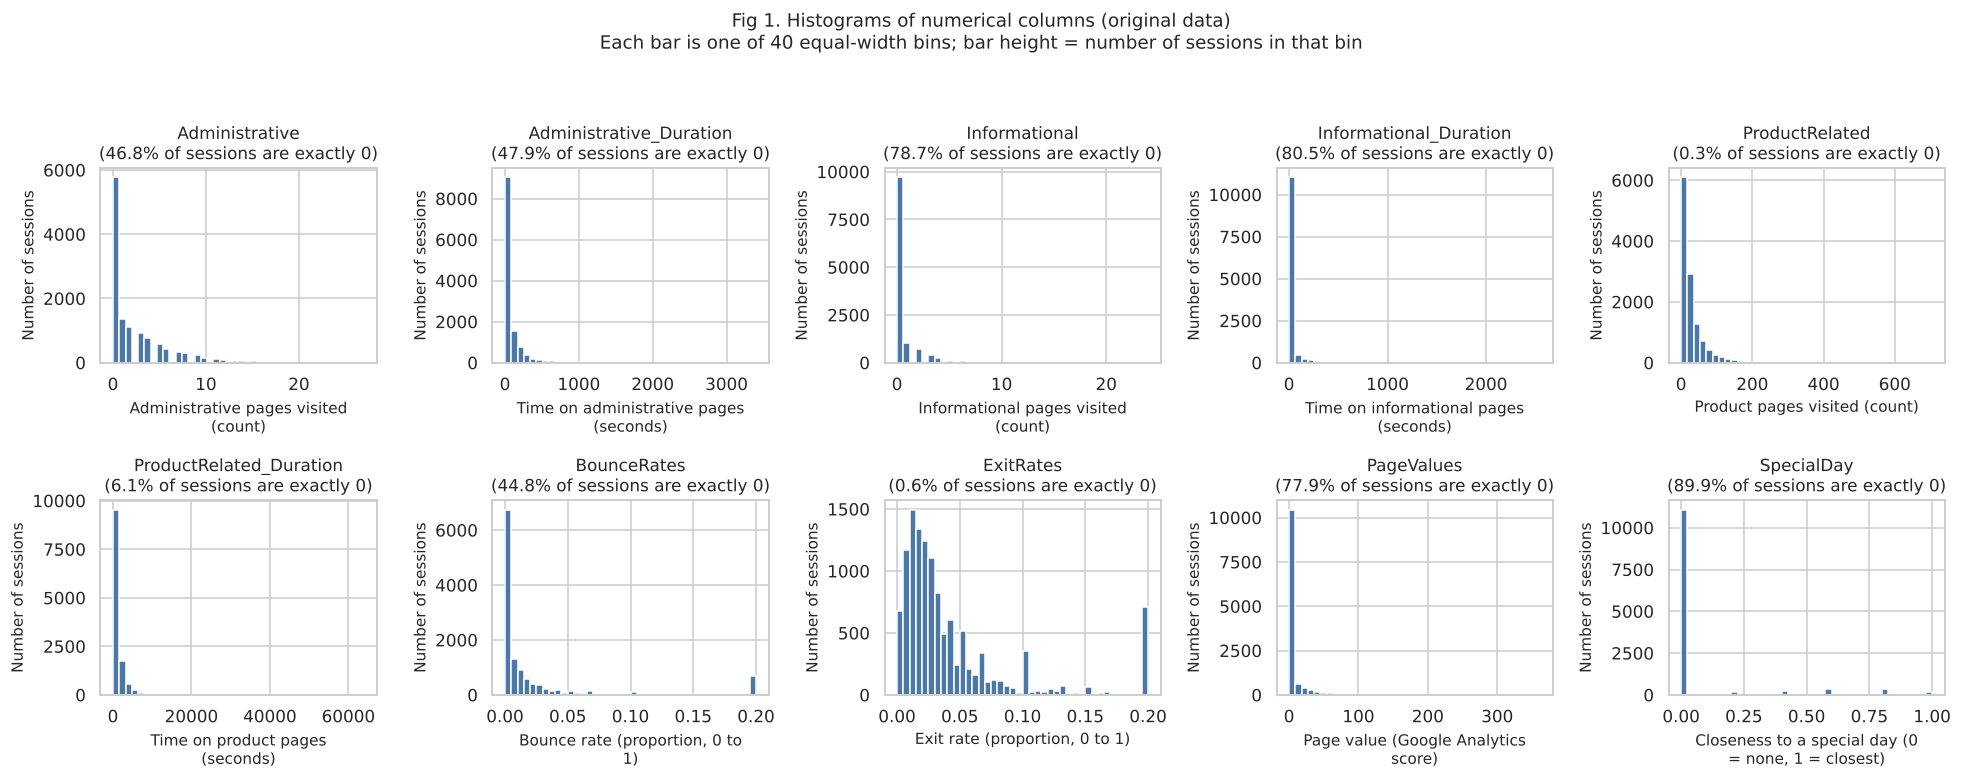

In [6]:
import textwrap

# Plain-English axis labels with units, used by every chart in this notebook
AXIS_LABEL = {
    "Administrative":          "Administrative pages visited (count)",
    "Administrative_Duration": "Time on administrative pages (seconds)",
    "Informational":           "Informational pages visited (count)",
    "Informational_Duration":  "Time on informational pages (seconds)",
    "ProductRelated":          "Product pages visited (count)",
    "ProductRelated_Duration": "Time on product pages (seconds)",
    "BounceRates":             "Bounce rate (proportion, 0 to 1)",
    "ExitRates":               "Exit rate (proportion, 0 to 1)",
    "PageValues":              "Page value (Google Analytics score)",
    "SpecialDay":              "Closeness to a special day (0 = none, 1 = closest)",
}
wrap = lambda text, width=30: textwrap.fill(text, width)

def hist_grid(data, cols, title, path, ncols=5, bins=40):
    """Histogram per column. x = value with unit, y = number of sessions; the title shows the share of exact zeros."""
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.4 * nrows))
    for ax, c in zip(axes.ravel(), cols):
        ax.hist(data[c], bins=bins, color="#4C78A8", edgecolor="white")
        zero_share = (data[c] == 0).mean() * 100
        ax.set_title(f"{c}\n({zero_share:.1f}% of sessions are exactly 0)")
        ax.set_xlabel(wrap(AXIS_LABEL[c])); ax.set_ylabel("Number of sessions")
    for ax in axes.ravel()[len(cols):]:
        ax.axis("off")
    fig.suptitle(f"{title}\nEach bar is one of {bins} equal-width bins; bar height = number of sessions in that bin", y=1.04, fontsize=12)
    fig.tight_layout(); fig.savefig(path, bbox_inches="tight"); plt.show()

hist_grid(raw, num_cols_raw, "Fig 1. Histograms of numerical columns (original data)",
          FIG_DIR / "fig01_hist_original.png")

**Interpretation.** Every numerical column has a spike at or near zero and a long right tail. These shapes will be hard for a generator to reproduce, so we need to keep them (rather than smooth them away) and to be careful with outliers.

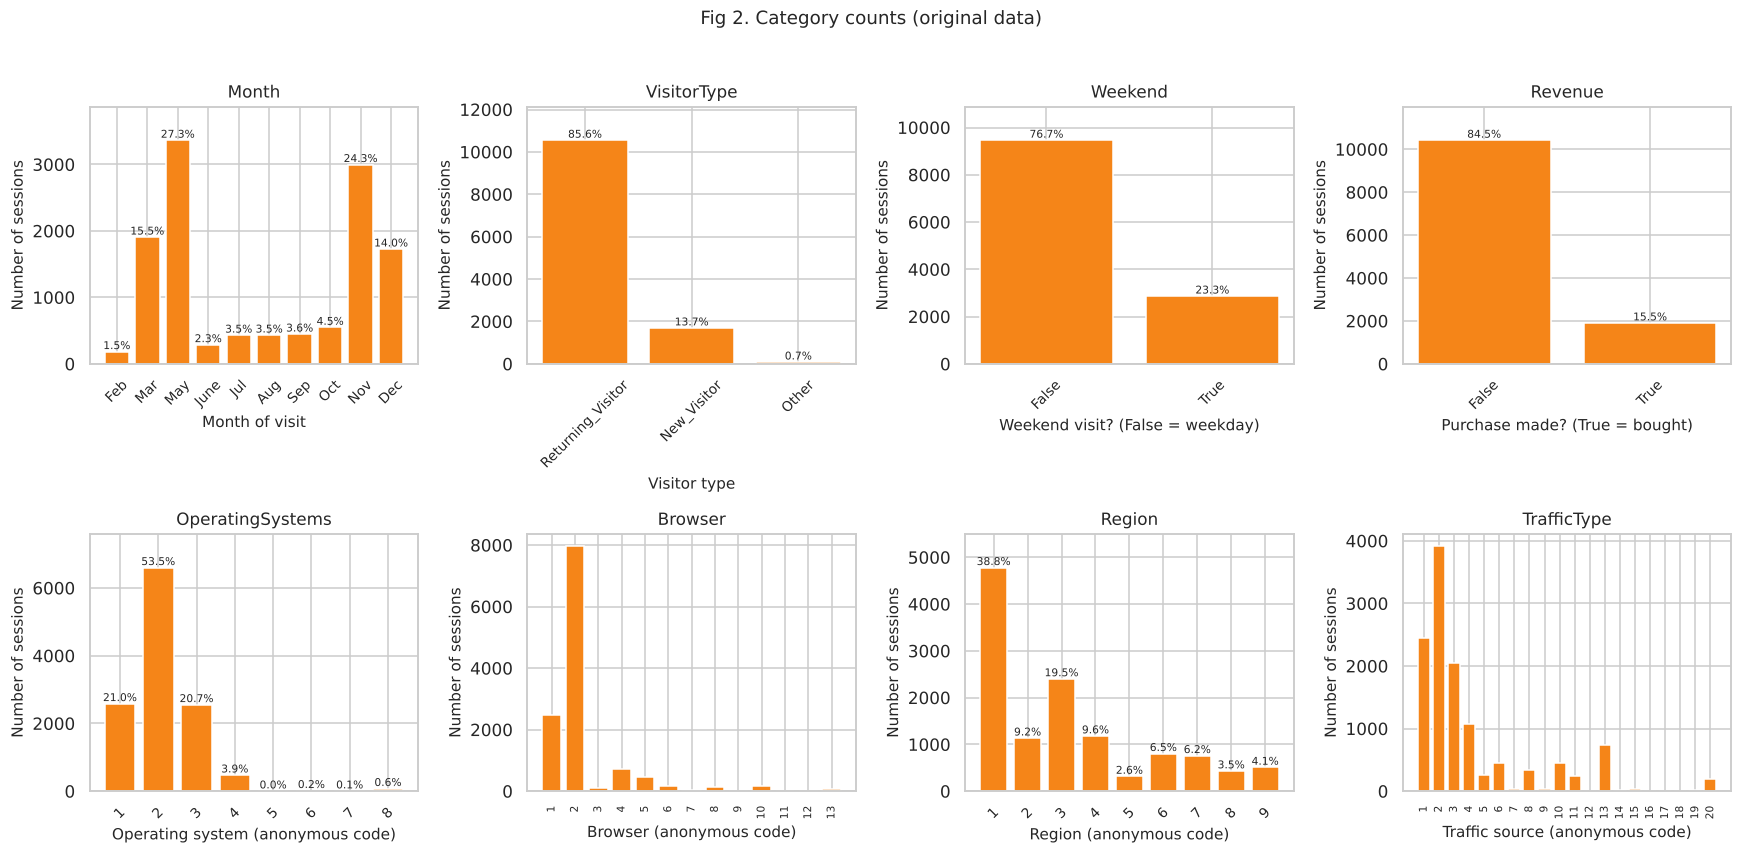

In [7]:
CAT_LABEL = {
    "Month": "Month of visit", "VisitorType": "Visitor type",
    "Weekend": "Weekend visit? (False = weekday)", "Revenue": "Purchase made? (True = bought)",
    "OperatingSystems": "Operating system (anonymous code)", "Browser": "Browser (anonymous code)",
    "Region": "Region (anonymous code)", "TrafficType": "Traffic source (anonymous code)",
}
MONTH_CAL = ["Feb", "Mar", "May", "June", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]   # calendar order

def bar_grid(data, cols, title, path, ncols=4):
    """Bar chart per category column. y = number of sessions; % of all sessions printed on bars when there are 10 or fewer bars."""
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 3.8 * nrows))
    for ax, c in zip(axes.ravel(), cols):
        vc = data[c].value_counts()
        if c == "Month":
            vc = vc.reindex([m for m in MONTH_CAL if m in vc.index])          # calendar order, not count order
        elif data[c].dtype != "object":
            vc = vc.sort_index()                                              # codes in numeric order
        pos = np.arange(len(vc))
        ax.bar(pos, vc.values, color="#F58518")
        ax.set_xticks(pos); ax.set_xticklabels(vc.index.astype(str))
        many = len(vc) > 10
        ax.tick_params(axis="x", rotation=90 if many else 45, labelsize=7 if many else 9)
        if not many:
            for x, v in zip(pos, vc.values):
                ax.text(x, v, f"{v / len(data) * 100:.1f}%", ha="center", va="bottom", fontsize=7)
            ax.set_ylim(0, vc.max() * 1.15)
        ax.set_title(c); ax.set_xlabel(wrap(CAT_LABEL[c], 34)); ax.set_ylabel("Number of sessions")
    for ax in axes.ravel()[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, y=1.02, fontsize=12)
    fig.tight_layout(); fig.savefig(path, bbox_inches="tight"); plt.show()

bar_grid(raw, cat_cols_raw, "Fig 2. Category counts (original data)", FIG_DIR / "fig02_bars_original.png")

**Interpretation.** The purchase outcome is imbalanced (about 1 in 6.5 sessions ends in a purchase), visits are concentrated in a few months (May, November, March and December), and most traffic comes from one operating system, one browser and a few traffic types. Any synthetic data must reproduce this imbalance to count as faithful.

## 3. Preprocessing

Every step below appends a row to the **preprocessing log** (what changed, how many rows or cells were affected, and why). The log is saved next to the cleaned data.

In [8]:
LOG = []
def log_step(step, action, affected, reason):
    """Record one preprocessing decision."""
    LOG.append({"step": step, "action": action, "rows_or_cells_affected": affected, "reason": reason})
    print(f"[{step}] {action} -> {affected}")

log_step("0 Load", "Loaded original file unchanged", f"{len(raw)} rows x {raw.shape[1]} cols",
         "Starting point; original is never modified")

[0 Load] Loaded original file unchanged -> 12330 rows x 18 cols


### 3.1 Missing values

In [9]:
n_missing = int(df.isna().sum().sum())
log_step("1 Missing values", "Checked all 18 columns; no imputation or deletion needed", f"{n_missing} missing cells",
         "Source reports no missing values and the check confirms it; imputing would only invent data")

[1 Missing values] Checked all 18 columns; no imputation or deletion needed -> 0 missing cells


**Decision.** No missing values exist, so nothing is imputed or dropped. Documenting this check is itself the required step.

### 3.2 Duplicates

In [10]:
dups = df[df.duplicated(keep="first")]
print("Duplicate rows (beyond first copy):", len(dups))
print("Share with purchase (Revenue=True):", int(dups["Revenue"].sum()))
print("Share with no page-time at all:",
      int((dups[["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]].sum(axis=1) == 0).sum()))
rev_before = df["Revenue"].mean()
df = df.drop_duplicates(keep="first").reset_index(drop=True)
log_step("2 Duplicates", "Dropped exact duplicate rows, kept first copy", f"{len(dups)} rows removed",
         "Identical rows add no information and would make the later exact-match privacy check against synthetic data ambiguous")
print(f"Purchase rate before: {rev_before:.4f}  after: {df['Revenue'].mean():.4f}")

Duplicate rows (beyond first copy): 125
Share with purchase (Revenue=True): 0
Share with no page-time at all: 125
[2 Duplicates] Dropped exact duplicate rows, kept first copy -> 125 rows removed
Purchase rate before: 0.1547  after: 0.1563


**Decision.** The source says every row is a different user's session, so identical rows are most likely coincidences, not double-logging. However, all of them are short sessions with no recorded time and none ended in a purchase, which suggests they are trivial single-page bounces. We still remove them because (a) they cannot be told apart from logging duplicates, and (b) the privacy check in Phase 4 needs a duplicate-free real table. The side effect is a slight rise in the purchase rate, noted above; this is recorded as a limitation.

### 3.3 Logical consistency checks

In [11]:
pages = df[["Administrative", "Informational", "ProductRelated"]].sum(axis=1)

# (a) sessions with zero page views in total: a session with no pages is not a valid session
zero_pages = int((pages == 0).sum())
# (b) pages visited but zero recorded time: expected for single-page visits, so only counted
cnt_dur = {n: int(((df[n] > 0) & (df[d] == 0)).sum()) for n, d in
           [("Administrative", "Administrative_Duration"),
            ("Informational", "Informational_Duration"),
            ("ProductRelated", "ProductRelated_Duration")]}
# (c) time recorded but no pages: impossible
dur_cnt = {n: int(((df[n] == 0) & (df[d] > 0)).sum()) for n, d in
           [("Administrative", "Administrative_Duration"),
            ("Informational", "Informational_Duration"),
            ("ProductRelated", "ProductRelated_Duration")]}
# (d) bounce rate above exit rate: unusual, kept and flagged
bounce_gt_exit = int((df["BounceRates"] > df["ExitRates"]).sum())

print("Rows with zero pages in total          :", zero_pages)
print("Pages > 0 but duration = 0 (kept)      :", cnt_dur)
print("Duration > 0 but pages = 0 (impossible):", dur_cnt)
print("BounceRates > ExitRates (kept, flagged):", bounce_gt_exit)

df = df[pages > 0].reset_index(drop=True)
log_step("3a Consistency", "Removed sessions with zero page views in total", f"{zero_pages} rows removed",
         "A session without any page view is contradictory and makes per-page ratios undefined")
log_step("3b Consistency", "Kept rows with pages > 0 but duration = 0; no change", f"{sum(cnt_dur.values())} cell-pairs",
         "Single-page visits have no measurable time on page, so this is expected, not an error")
log_step("3c Consistency", "Kept rows with BounceRates > ExitRates; no change", f"{bounce_gt_exit} rows",
         "Cannot be verified as errors from the data alone; removing them would be arbitrary. Flagged as a limitation")

Rows with zero pages in total          : 6
Pages > 0 but duration = 0 (kept)      : {'Administrative': 135, 'Informational': 226, 'ProductRelated': 592}
Duration > 0 but pages = 0 (impossible): {'Administrative': 0, 'Informational': 0, 'ProductRelated': 0}
BounceRates > ExitRates (kept, flagged): 175
[3a Consistency] Removed sessions with zero page views in total -> 6 rows removed
[3b Consistency] Kept rows with pages > 0 but duration = 0; no change -> 953 cell-pairs
[3c Consistency] Kept rows with BounceRates > ExitRates; no change -> 175 rows


**Decision.** Rows with no page views at all are removed because they are internally contradictory. Zero duration with pages visited is normal for one-page visits, so it is kept. Rows where the bounce rate exceeds the exit rate look unusual, but we cannot prove they are wrong, so they are kept and flagged instead of being silently dropped.

### 3.4 Outlier detection (IQR and Z-score)

In [12]:
def outlier_table(data, cols):
    """IQR (1.5x) and |Z|>3 outlier counts plus a check for degenerate IQR fences."""
    rows = []
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        z = np.abs(stats.zscore(data[c]))
        rows.append({"column": c, "Q1": q1, "Q3": q3,
                     "IQR_outliers": int(((data[c] < lo) | (data[c] > hi)).sum()),
                     "Z>3_outliers": int((z > 3).sum()),
                     "share_zero_%": round((data[c] == 0).mean() * 100, 1),
                     "fence_degenerate(Q3=0)": bool(q3 == 0),
                     "p99.5": data[c].quantile(0.995), "max": data[c].max()})
    return pd.DataFrame(rows).set_index("column")

out_before = outlier_table(df, num_cols_raw)
display(out_before.round(3))

,Q1,Q3,IQR_outliers,Z>3_outliers,share_zero_%,fence_degenerate(Q3=0),p99.5,max
column,,,,,,,,
Administrative,0.000,4.000,404,213,46.2,False,16.000,27.000
Administrative_Duration,0.000,94.750,1147,229,47.3,False,1178.967,3398.750
Informational,0.000,0.000,2631,260,78.4,True,7.000,24.000
Informational_Duration,0.000,0.000,2405,229,80.3,True,1005.421,2549.375
ProductRelated,8.000,38.000,1007,236,0.3,False,282.010,705.000
ProductRelated_Duration,193.708,1477.565,951,217,5.1,False,11246.177,63973.522
BounceRates,0.000,0.017,1422,587,45.2,False,0.200,0.200
ExitRates,0.014,0.048,1319,593,0.6,False,0.200,0.200
PageValues,0.000,0.000,2730,256,77.6,True,111.265,361.764


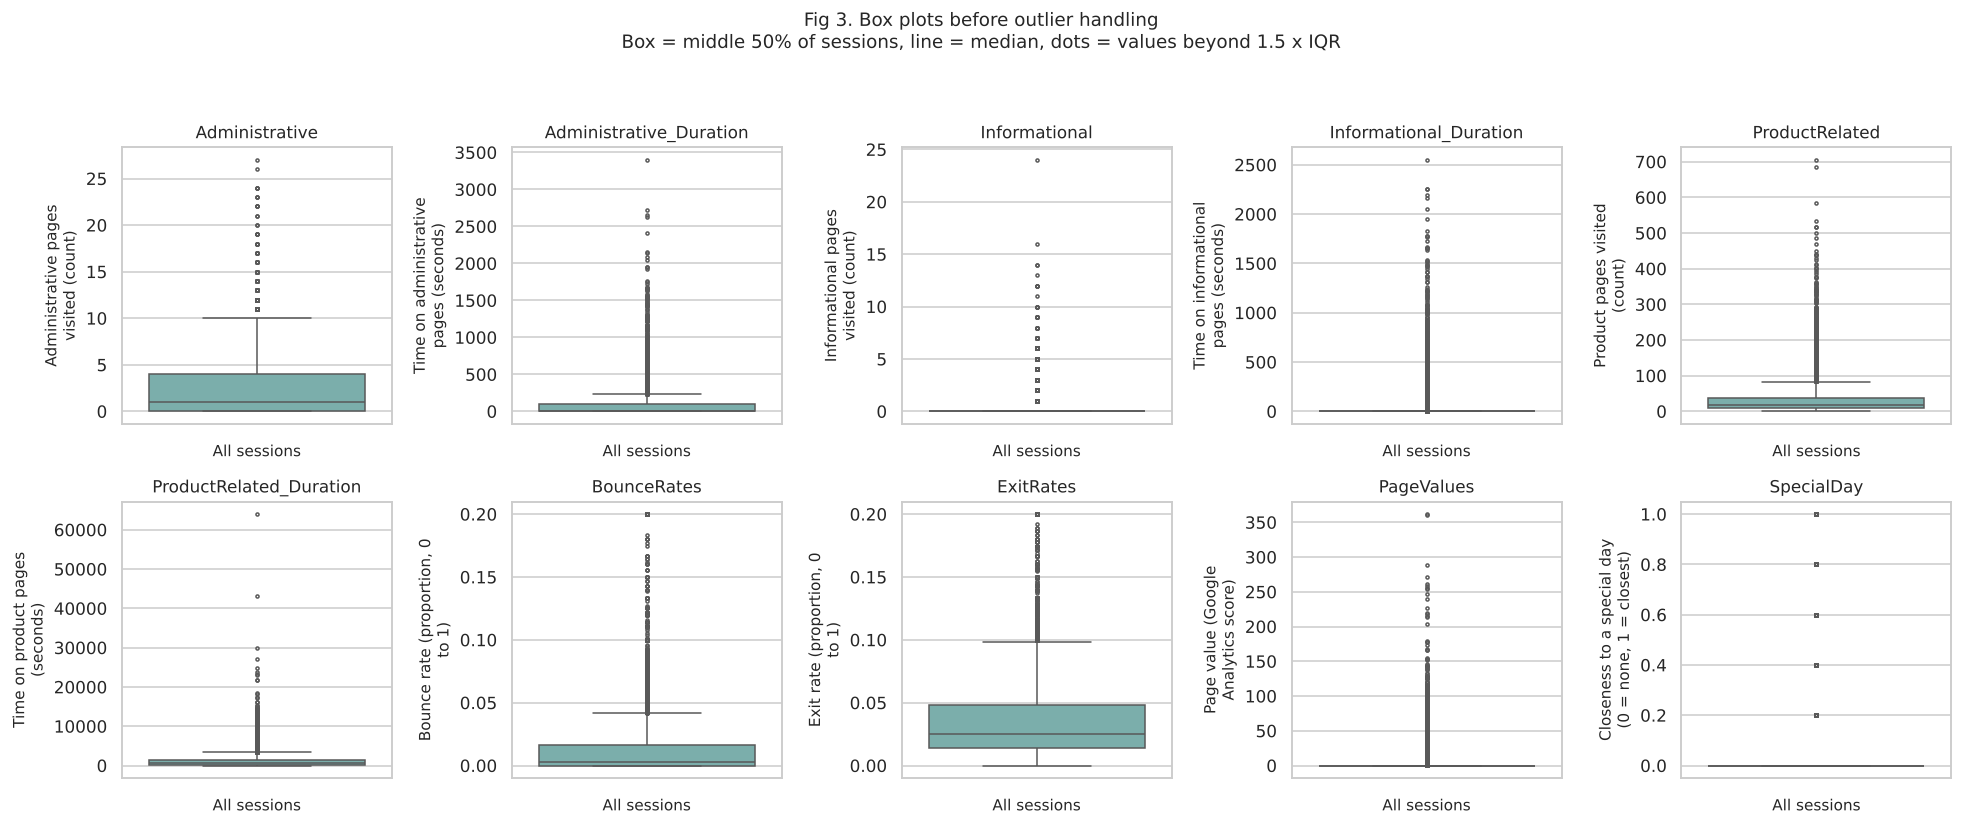

In [13]:
def box_grid(data, cols, title, path, ncols=5):
    """Box plot per column. y = value with unit; box = middle 50% of sessions, line = median, dots = values beyond 1.5 x IQR."""
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.6 * nrows))
    for ax, c in zip(np.atleast_1d(axes).ravel(), cols):
        sns.boxplot(y=data[c], ax=ax, color="#72B7B2", fliersize=2)
        ax.set_title(c); ax.set_ylabel(wrap(AXIS_LABEL[c], 26)); ax.set_xlabel("All sessions")
    fig.suptitle(f"{title}\nBox = middle 50% of sessions, line = median, dots = values beyond 1.5 x IQR", y=1.04, fontsize=12)
    fig.tight_layout(); fig.savefig(path, bbox_inches="tight"); plt.show()

box_grid(df, num_cols_raw, "Fig 3. Box plots before outlier handling", FIG_DIR / "fig03_box_before.png")

**Interpretation.** IQR flags thousands of rows in columns such as `Informational`, `PageValues` and `SpecialDay`, but in those columns Q3 is zero (most sessions are zero), so the IQR fences collapse to zero and every non-zero value looks like an outlier. These are real, informative sessions (for example, about 81% of purchase sessions have a non-zero `PageValues`, against about 12% of non-purchase sessions), not errors. Only the extreme tails of the page-count and duration columns are suspicious: for example, a product-page duration of about 64,000 seconds (over 17 hours) is far beyond the 99.5th percentile and may come from a session left open or from a bot.

### 3.5 Outlier decision: cap extreme tails, keep everything else

,cap_value,values_capped,max_before
column,,,
ProductRelated,282.00,61,705.00
ProductRelated_Duration,11246.18,61,63973.52
Administrative_Duration,1178.97,61,3398.75
Informational_Duration,1005.42,61,2549.38


[4 Outliers] Capped ProductRelated at the 99.5th percentile (282.0) -> 61 values
[4 Outliers] Capped ProductRelated_Duration at the 99.5th percentile (11246.2) -> 61 values
[4 Outliers] Capped Administrative_Duration at the 99.5th percentile (1179.0) -> 61 values
[4 Outliers] Capped Informational_Duration at the 99.5th percentile (1005.4) -> 61 values
[4 Outliers] Kept all other numeric columns uncapped (counts, rates, PageValues, SpecialDay) -> 0 changes


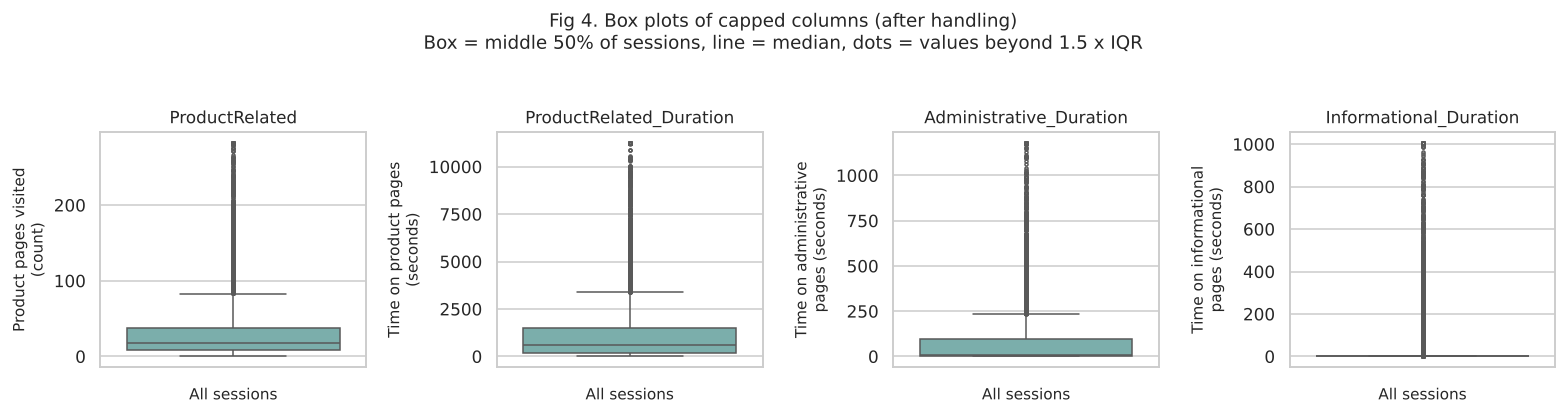

In [14]:
CAP_PCT = 0.995
CAP_COLS = ["ProductRelated", "ProductRelated_Duration", "Administrative_Duration", "Informational_Duration"]

def cap_upper(data, cols, pct):
    """Winsorise the upper tail at the given percentile; return capped copy and a report."""
    out, rep = data.copy(), []
    for c in cols:
        cap = data[c].quantile(pct)
        if data[c].dtype.kind == "i":
            cap = int(np.floor(cap))
        n = int((data[c] > cap).sum())
        out[c] = data[c].clip(upper=cap)
        rep.append({"column": c, "cap_value": cap, "values_capped": n, "max_before": data[c].max()})
    return out, pd.DataFrame(rep).set_index("column")

df, cap_report = cap_upper(df, CAP_COLS, CAP_PCT)
display(cap_report.round(2))
for c, r in cap_report.iterrows():
    log_step("4 Outliers", f"Capped {c} at the 99.5th percentile ({r['cap_value']:.1f})", f"{int(r['values_capped'])} values",
             "Extreme tail likely reflects idle or bot sessions and would dominate means, KDEs and generator fitting; rows are kept")
log_step("4 Outliers", "Kept all other numeric columns uncapped (counts, rates, PageValues, SpecialDay)", "0 changes",
         "Their IQR 'outliers' are real non-zero behaviour in zero-inflated columns, not errors")
box_grid(df, CAP_COLS, "Fig 4. Box plots of capped columns (after handling)", FIG_DIR / "fig04_box_after.png", ncols=4)

**Decision.** Winsorising (capping) the top 0.5% of four columns keeps every row, so no purchase or visitor is lost, while stopping a handful of extreme sessions from dominating means and distribution plots. Capping at the 99.5th percentile affects about 60 values per column. The original uncapped values remain in the original file, and the effect is stated in the report. The other columns are kept as they are because their apparent outliers are valid behaviour.

### 3.6 Fix data types and labels

In [15]:
# (a) Standardise inconsistent month label and make Month an ordered category
df["Month"] = df["Month"].replace({"June": "Jun"})
MONTH_ORDER = ["Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]   # months present in the data
assert set(df["Month"]) == set(MONTH_ORDER)
log_step("5a Labels", "Renamed 'June' to 'Jun' in Month", f"{int((raw['Month'] == 'June').sum())} raw rows", "Make month labels consistent (3 letters)")

# (b) Boolean columns -> readable labels
df["Weekend"] = df["Weekend"].map({True: "Weekend", False: "Weekday"})
df["Revenue"] = df["Revenue"].map({True: "Purchase", False: "No_Purchase"})
log_step("5b Types", "Converted Weekend and Revenue from bool to labelled categories", "2 columns",
         "Readable labels for charts and Power BI slicers; avoids True/False being treated as numbers")

# (c) Integer-coded categories -> string categories with a prefix
for col, prefix in [("OperatingSystems", "OS_"), ("Browser", "Browser_"), ("Region", "Region_"), ("TrafficType", "Traffic_")]:
    df[col] = prefix + df[col].astype(str)
log_step("5c Types", "Converted OperatingSystems, Browser, Region, TrafficType from int to labelled categories", "4 columns",
         "They are anonymous codes, not quantities; averaging them would be meaningless")

# (d) Numeric dtypes: counts stay integer, durations/rates float
int_cols = ["Administrative", "Informational", "ProductRelated"]
df[int_cols] = df[int_cols].astype(int)
log_step("5d Types", "Kept page counts as integers and durations, rates, PageValues, SpecialDay as floats", "10 columns", "Matches what each variable measures")

[5a Labels] Renamed 'June' to 'Jun' in Month -> 288 raw rows
[5b Types] Converted Weekend and Revenue from bool to labelled categories -> 2 columns
[5c Types] Converted OperatingSystems, Browser, Region, TrafficType from int to labelled categories -> 4 columns
[5d Types] Kept page counts as integers and durations, rates, PageValues, SpecialDay as floats -> 10 columns


### 3.7 Derived attributes

In [16]:
# Four numeric and two categorical features that make domain sense for web-session data
df["Total_Pages"] = df["Administrative"] + df["Informational"] + df["ProductRelated"]
df["Total_Duration"] = df["Administrative_Duration"] + df["Informational_Duration"] + df["ProductRelated_Duration"]
df["Avg_Time_Per_Page"] = df["Total_Duration"] / df["Total_Pages"]          # seconds per page (Total_Pages >= 1 after step 3a)
df["Product_Page_Share"] = df["ProductRelated"] / df["Total_Pages"]          # share of the session spent on product pages

QUARTER_MAP = {"Feb": "Q1", "Mar": "Q1", "May": "Q2", "Jun": "Q2", "Jul": "Q3", "Aug": "Q3", "Sep": "Q3",
               "Oct": "Q4", "Nov": "Q4", "Dec": "Q4"}
df["Quarter"] = df["Month"].map(QUARTER_MAP)

# Session length band: tertiles of Total_Pages
band_edges = df["Total_Pages"].quantile([1/3, 2/3]).tolist()
df["Session_Length_Band"] = pd.cut(df["Total_Pages"], bins=[0, band_edges[0], band_edges[1], np.inf],
                                   labels=["Short", "Medium", "Long"], include_lowest=True).astype(str)
print("Session length band edges (pages):", [round(e, 1) for e in band_edges])
print(df["Session_Length_Band"].value_counts().to_string())

for name, why in [("Total_Pages", "Overall session size across the three page types"),
                  ("Total_Duration", "Total time spent in the session (seconds)"),
                  ("Avg_Time_Per_Page", "Engagement intensity: seconds per page"),
                  ("Product_Page_Share", "How product-focused the session was (0 to 1)"),
                  ("Quarter", "Groups the 10 months into quarters for coarser trend analysis"),
                  ("Session_Length_Band", "Short / Medium / Long sessions (tertiles of Total_Pages) for group comparisons")]:
    log_step("6 Derived", f"Created {name}", f"{len(df)} rows", why)

Session length band edges (pages): [12.0, 33.0]
Session_Length_Band
Short     4149
Medium    4047
Long      4003
[6 Derived] Created Total_Pages -> 12199 rows
[6 Derived] Created Total_Duration -> 12199 rows
[6 Derived] Created Avg_Time_Per_Page -> 12199 rows
[6 Derived] Created Product_Page_Share -> 12199 rows
[6 Derived] Created Quarter -> 12199 rows
[6 Derived] Created Session_Length_Band -> 12199 rows


**Why these features.** Total pages, total duration and time per page describe how engaged a visitor was, and the product-page share separates browsing from product research; all are meaningful for predicting purchases. `Quarter` and `Session_Length_Band` give two extra categorical groupings for the Scenario analyses. Note for Phase 3: the derived columns are exact functions of the base columns, so they should be **recomputed** from the synthetic base columns, not generated independently, otherwise they could contradict each other.

### 3.8 Final validation and column order

In [17]:
BASE_NUM = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
DERIVED_NUM = ["Total_Pages", "Total_Duration", "Avg_Time_Per_Page", "Product_Page_Share"]
CAT_COLS = ["Month", "Quarter", "VisitorType", "Weekend", "OperatingSystems", "Browser", "Region",
            "TrafficType", "Session_Length_Band", "Revenue"]
df = df[BASE_NUM + DERIVED_NUM + CAT_COLS]

# Validity rules (the synthetic data in Phase 3 must satisfy the same rules)
assert df.isna().sum().sum() == 0
assert not df.duplicated().any()
assert (df[BASE_NUM + DERIVED_NUM] >= 0).all().all()
assert df[["BounceRates", "ExitRates", "SpecialDay", "Product_Page_Share"]].le(1).all().all()
assert (df["Total_Pages"] >= 1).all()
assert set(df["Month"]) <= set(MONTH_ORDER)

print("Cleaned shape:", df.shape, "| numeric:", len(BASE_NUM + DERIVED_NUM), "| categorical:", len(CAT_COLS))
display(df.head())
display(df.dtypes.to_frame("dtype").T)

Cleaned shape: (12199, 24) | numeric: 14 | categorical: 10


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month,Quarter,VisitorType,Weekend,OperatingSystems,Browser,Region,TrafficType,Session_Length_Band,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,Feb,Q1,Returning_Visitor,Weekday,OS_1,Browser_1,Region_1,Traffic_1,Short,No_Purchase
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,Feb,Q1,Returning_Visitor,Weekday,OS_2,Browser_2,Region_1,Traffic_2,Short,No_Purchase
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,Feb,Q1,Returning_Visitor,Weekday,OS_4,Browser_1,Region_9,Traffic_3,Short,No_Purchase
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,Feb,Q1,Returning_Visitor,Weekday,OS_3,Browser_2,Region_2,Traffic_4,Short,No_Purchase
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,Feb,Q1,Returning_Visitor,Weekend,OS_3,Browser_3,Region_1,Traffic_4,Short,No_Purchase


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month,Quarter,VisitorType,Weekend,OperatingSystems,Browser,Region,TrafficType,Session_Length_Band,Revenue
dtype,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,...,object,object,object,object,object,object,object,object,object,object


### 3.9 Before vs. after cleaning

In [18]:
cmp_cols = ["ProductRelated", "ProductRelated_Duration", "Administrative_Duration", "Informational_Duration", "PageValues"]
cmp = pd.DataFrame({"mean_before": raw[cmp_cols].mean(), "mean_after": df[cmp_cols].mean(),
                    "std_before": raw[cmp_cols].std(), "std_after": df[cmp_cols].std(),
                    "max_before": raw[cmp_cols].max(), "max_after": df[cmp_cols].max()})
display(cmp.round(2))
print(f"Rows: {len(raw)} -> {len(df)}  (removed {len(raw) - len(df)}, {100 * (len(raw) - len(df)) / len(raw):.2f}%)")
print(f"Purchase rate: {raw['Revenue'].mean():.4f} -> {(df['Revenue'] == 'Purchase').mean():.4f}")

,mean_before,mean_after,std_before,std_after,max_before,max_after
ProductRelated,31.73,31.57,44.48,40.69,705.00,282.00
ProductRelated_Duration,1194.75,1183.08,1913.67,1652.53,63973.52,11246.18
Administrative_Duration,80.82,79.49,176.78,157.52,3398.75,1178.97
Informational_Duration,34.47,32.77,140.75,120.16,2549.38,1005.42
PageValues,5.89,5.95,18.57,18.66,361.76,361.76


Rows: 12330 -> 12199  (removed 131, 1.06%)
Purchase rate: 0.1547 -> 0.1564


**Interpretation.** Means and standard deviations of the capped columns fall a little, mostly the standard deviation, which is expected because only the extreme tail was changed. `PageValues` is untouched, so the strongest purchase signal is intact. The share of purchase sessions rises only slightly after removing the zero-activity duplicates.

## 4. Save outputs and confirm the original is untouched

In [19]:
df.to_csv(CLEAN_PATH, index=False)
log_df = pd.DataFrame(LOG)
log_df.to_csv(LOG_PATH, index=False)
display(log_df)

# Verify the original file was not modified
assert sha256(ORIG_PATH) == ORIG_HASH, "Original file changed!"
print("Original file unchanged (hash matches).")
print("Saved:", CLEAN_PATH.relative_to(ROOT), "and", LOG_PATH.relative_to(ROOT))

,step,action,rows_or_cells_affected,reason
0,0 Load,Loaded original file unchanged,12330 rows x 18 cols,Starting point; original is never modified
1,1 Missing values,Checked all 18 columns; no imputation or delet...,0 missing cells,Source reports no missing values and the check...
2,2 Duplicates,"Dropped exact duplicate rows, kept first copy",125 rows removed,Identical rows add no information and would ma...
3,3a Consistency,Removed sessions with zero page views in total,6 rows removed,A session without any page view is contradicto...
4,3b Consistency,Kept rows with pages > 0 but duration = 0; no ...,953 cell-pairs,Single-page visits have no measurable time on ...
5,3c Consistency,Kept rows with BounceRates > ExitRates; no change,175 rows,Cannot be verified as errors from the data alo...
6,4 Outliers,Capped ProductRelated at the 99.5th percentile...,61 values,Extreme tail likely reflects idle or bot sessi...
7,4 Outliers,Capped ProductRelated_Duration at the 99.5th p...,61 values,Extreme tail likely reflects idle or bot sessi...
8,4 Outliers,Capped Administrative_Duration at the 99.5th p...,61 values,Extreme tail likely reflects idle or bot sessi...
9,4 Outliers,Capped Informational_Duration at the 99.5th pe...,61 values,Extreme tail likely reflects idle or bot sessi...


Original file unchanged (hash matches).
Saved: data/cleaned/online_shoppers_cleaned.csv and data/cleaned/preprocessing_log.csv


## 5. Summary of Phase 2
- Original: 12,330 rows x 18 columns, no missing values; cleaned file saved separately.
- Rows removed: exact duplicates and zero-page sessions (see log for counts); no rows removed for outliers.
- Outliers: extreme tails of four columns capped at the 99.5th percentile; zero-inflated columns left as they are.
- Types and labels: integer-coded and boolean columns converted to labelled categories; `June` renamed `Jun`.
- Derived: `Total_Pages`, `Total_Duration`, `Avg_Time_Per_Page`, `Product_Page_Share`, `Quarter`, `Session_Length_Band`.
- Output: 14 numerical and 10 categorical columns in `data/cleaned/online_shoppers_cleaned.csv`, ready for synthetic generation in Phase 3.